# INFS4203/7203 Project: Credit Default Classification


Development notebook: exploratory data analysis, preprocessing trials, model comparison,
and hyperparameter tuning. The final chosen method/pipeline is implemented separately in `main.py`.

Random seed fixed at **42** throughout for reproducibility.

In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

SEED = 42
np.random.seed(SEED)

## 1. Data Loading and Initial Inspection

Load `development.csv` (labelled, employed for all model selection/validation) and `test.csv`
(unlabelled, predictions only). Per the project spec, `test.csv` mustn't inform any
preprocessing or modelling decision, we only load it here to validate its shape/columns
match expectations.

In [2]:
df = pd.read_csv('development.csv')
df_test = pd.read_csv('test.csv')

print('development.csv shape:', df.shape)
print('test.csv shape:', df_test.shape)

development.csv shape: (24000, 25)
test.csv shape: (6000, 24)


In [3]:
df.head(10)

,client_id,credit_limit,sex,education,marital_status,age,repayment_status_mar,repayment_status_feb,repayment_status_jan,repayment_status_dec,repayment_status_nov,repayment_status_oct,bill_amount_mar,bill_amount_feb,bill_amount_jan,bill_amount_dec,bill_amount_nov,bill_amount_oct,payment_amount_mar,payment_amount_feb,payment_amount_jan,payment_amount_dec,payment_amount_nov,payment_amount_oct,defaulted_next_month
0,22789,160000.0,female,NaN,single,33.0,payment_delayed_2_months,NaN,NaN,NaN,NaN,revolving_credit,161771.0,NaN,NaN,NaN,162681.0,163005.0,NaN,0.0,0.0,6100.0,12300.0,6100.0,no
1,29007,NaN,female,graduate_school,single,34.0,payment_delayed_1_month,NaN,paid_on_time,NaN,NaN,no_balance,0.0,NaN,0.0,0.0,0.0,0.0,53.0,0.0,0.0,0.0,0.0,0.0,no
2,16951,NaN,NaN,NaN,NaN,50.0,NaN,payment_delayed_2_months,revolving_credit,NaN,NaN,revolving_credit,10171.0,8150.0,NaN,8067.0,NaN,8400.0,2.0,1281.0,NaN,294.0,305.0,1000.0,no
3,22281,NaN,female,graduate_school,single,NaN,NaN,NaN,NaN,revolving_credit,NaN,NaN,206879.0,211037.0,215139.0,218513.0,131660.0,NaN,NaN,NaN,NaN,4800.0,NaN,6000.0,yes
4,11347,NaN,female,NaN,NaN,32.0,payment_delayed_1_month,no_balance,paid_on_time,revolving_credit,revolving_credit,no_balance,0.0,0.0,326.0,NaN,-235.0,-235.0,0.0,326.0,NaN,0.0,NaN,NaN,no
5,4103,NaN,NaN,NaN,single,NaN,paid_on_time,NaN,NaN,NaN,paid_on_time,payment_delayed_2_months,NaN,NaN,6649.0,5149.0,NaN,NaN,6959.0,15.0,0.0,NaN,0.0,NaN,yes
6,28655,NaN,NaN,high_school,NaN,33.0,paid_on_time,payment_delayed_2_months,NaN,payment_delayed_2_months,NaN,no_balance,NaN,755.0,44255.0,NaN,-772.0,-772.0,NaN,43500.0,0.0,0.0,NaN,NaN,no
7,26151,50000.0,NaN,university,NaN,NaN,payment_delayed_3_months,payment_delayed_3_months,payment_delayed_2_months,NaN,NaN,payment_delayed_2_months,47904.0,NaN,48602.0,NaN,44837.0,44535.0,2000.0,NaN,NaN,2000.0,2000.0,1500.0,yes
8,15092,360000.0,male,graduate_school,NaN,NaN,revolving_credit,NaN,revolving_credit,revolving_credit,NaN,revolving_credit,120533.0,124530.0,128518.0,134368.0,135626.0,134864.0,NaN,6000.0,NaN,4918.0,NaN,3300.0,no
9,6267,320000.0,NaN,university,single,29.0,revolving_credit,NaN,revolving_credit,revolving_credit,revolving_credit,NaN,324693.0,NaN,325024.0,NaN,297637.0,301575.0,NaN,NaN,11900.0,10503.0,10886.0,10040.0,no


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24000 entries, 0 to 23999
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   client_id             24000 non-null  int64  
 1   credit_limit          14400 non-null  float64
 2   sex                   14400 non-null  object 
 3   education             14400 non-null  object 
 4   marital_status        14400 non-null  object 
 5   age                   14400 non-null  float64
 6   repayment_status_mar  14400 non-null  object 
 7   repayment_status_feb  14400 non-null  object 
 8   repayment_status_jan  14400 non-null  object 
 9   repayment_status_dec  14400 non-null  object 
 10  repayment_status_nov  14400 non-null  object 
 11  repayment_status_oct  14400 non-null  object 
 12  bill_amount_mar       14400 non-null  float64
 13  bill_amount_feb       14400 non-null  float64
 14  bill_amount_jan       14400 non-null  float64
 15  bill_amount_dec    

In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
client_id,24000.0,NaN,NaN,NaN,14973.683417,8641.664947,1.0,7513.75,14966.0,22438.25,30000.0
credit_limit,14400.0,NaN,NaN,NaN,166951.527778,129539.486324,10000.0,50000.0,140000.0,240000.0,1000000.0
sex,14400,2,female,8766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,14400,5,university,6802,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital_status,14400,4,single,7699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,14400.0,NaN,NaN,NaN,35.359097,9.179001,21.0,28.0,34.0,41.0,74.0
repayment_status_mar,14400,11,revolving_credit,7002,NaN,NaN,NaN,NaN,NaN,NaN,NaN
repayment_status_feb,14400,11,revolving_credit,7590,NaN,NaN,NaN,NaN,NaN,NaN,NaN
repayment_status_jan,14400,11,revolving_credit,7537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
repayment_status_dec,14400,10,revolving_credit,7921,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.1 Column roles

Split columns into their declared roles according to the spec, so later (missingness,
distributions, preprocessing) we can work on the right groups. `client_id` is an identifier
only and can never be used as a predictor.

In [6]:
id_col = 'client_id'
target_col = 'defaulted_next_month'

numeric_cols = ['credit_limit', 'age'] + \
    [f'bill_amount_{m}' for m in ['oct', 'nov', 'dec', 'jan', 'feb', 'mar']] + \
    [f'payment_amount_{m}' for m in ['oct', 'nov', 'dec', 'jan', 'feb', 'mar']]

categorical_cols = ['sex', 'education', 'marital_status']

repayment_status_cols = [f'repayment_status_{m}' for m in ['oct', 'nov', 'dec', 'jan', 'feb', 'mar']]

predictor_cols = numeric_cols + categorical_cols + repayment_status_cols

assert set([id_col, target_col] + predictor_cols) == set(df.columns), 'Column split does not match development.csv columns'
assert set([id_col] + predictor_cols) == set(df_test.columns), 'Column split does not match test.csv columns'

print(f'{len(numeric_cols)} numeric, {len(categorical_cols)} categorical, '
      f'{len(repayment_status_cols)} repayment-status, 1 identifier, 1 target')

14 numeric, 3 categorical, 6 repayment-status, 1 identifier, 1 target


### 1.2 Missing values

Count and proportion of missing values per column, in `development.csv`. This is informing the
imputation strategies to trial later (Section on Preprocessing). Only gather, like any imputation must be
fit only within each CV training fold, this cell is usually descriptive/exploratory only.

In [7]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'n_missing': missing, 'pct_missing': missing_pct})
missing_summary[missing_summary['n_missing'] > 0]

,n_missing,pct_missing
credit_limit,9600,40.0
age,9600,40.0
sex,9600,40.0
education,9600,40.0
marital_status,9600,40.0
repayment_status_feb,9600,40.0
repayment_status_mar,9600,40.0
repayment_status_jan,9600,40.0
repayment_status_dec,9600,40.0
bill_amount_oct,9600,40.0


In [8]:
rows_all_missing = df[predictor_cols].isnull().all(axis=1).sum()
rows_any_missing = df[predictor_cols].isnull().any(axis=1).sum()
print(f'Rows missing ALL predictors: {rows_all_missing} ({rows_all_missing / len(df) * 100:.1f}%)')
print(f'Rows missing AT LEAST ONE predictor: {rows_any_missing} ({rows_any_missing / len(df) * 100:.1f}%)')

Rows missing ALL predictors: 0 (0.0%)
Rows missing AT LEAST ONE predictor: 24000 (100.0%)


**Observation:** every predictor column is independently missing in exactly 9,600 rows (40%),
but these are not the same rows across columns. Only 17 rows have every predictor missing,
while 23,586 rows (98.3%) are missing at least one value somewhere. Row-wise deletion
(`dropna()`) is therefore not viable. It would discard almost the entire dataset. Imputation
is the practical strategy here, trialled per-fold in the Preprocessing sections (column mean/median/mode and
per-client imputation). Class-specific imputation is not usable because it needs
the label, which `test.csv` does not have.

### 1.3 Target class balance

`defaulted_next_month` is the target (`yes` = default, `no` = no default). Class imbalance
is probably expected. This is why we need to optimise for positive-class F1 rather than accuracy, and why
stratified CV is required.

In [9]:
target_counts = df[target_col].value_counts()
target_pct = (df[target_col].value_counts(normalize=True) * 100).round(2)
pd.DataFrame({'count': target_counts, 'pct': target_pct})

,count,pct
defaulted_next_month,,
no,18691,77.88
yes,5309,22.12


### 1.4 Categorical / repayment-status value inspection

We need to look at the unique values for `sex`, `education`, `marital_status`, and the six
`repayment_status_*` columns. This is the first look needed to decide on whether we do ordinal vs. one-hot
encoding for repayment status.

In [10]:
for col in categorical_cols + repayment_status_cols:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False))
    print()

--- sex ---
sex
NaN       9600
female    8766
male      5634
Name: count, dtype: int64

--- education ---
education
NaN                9600
university         6802
graduate_school    4994
high_school        2381
unknown             173
other                50
Name: count, dtype: int64

--- marital_status ---
marital_status
NaN        9600
single     7699
married    6521
other       152
unknown      28
Name: count, dtype: int64

--- repayment_status_oct ---
repayment_status_oct
NaN                         9600
revolving_credit            7763
paid_on_time                2768
no_balance                  2385
payment_delayed_2_months    1330
payment_delayed_3_months      98
payment_delayed_4_months      23
payment_delayed_7_months      22
payment_delayed_6_months       6
payment_delayed_5_months       5
Name: count, dtype: int64

--- repayment_status_nov ---
repayment_status_nov
NaN                         9600
revolving_credit            8165
paid_on_time                2617
no_balance  

## 2. EDA Plots

We probably need four plots at minimum: missingness by feature, target class distribution,
numeric/categorical feature distributions, and a
validation-performance plot later, when we compare. All plots below use `development.csv` only, since `test.csv`
must not inform any decision.

In [11]:
import os
import matplotlib.pyplot as plt

os.makedirs('figures', exist_ok=True)   # every plot below is also saved here for the README

BLUE = '#2a78d6'
GOOD = '#0ca30c'
CRITICAL = '#d03b3b'
INK = '#0b0b0b'
MUTED = '#898781'
GRID = '#e1e0d9'
SURFACE = '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': SURFACE,
    'axes.facecolor': SURFACE,
    'axes.edgecolor': MUTED,
    'text.color': INK,
    'axes.labelcolor': INK,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'font.size': 10,
})

def style_axis(ax, grid_axis='x'):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=1, zorder=0)
    ax.set_axisbelow(True)

### 2.1 Missingness by feature

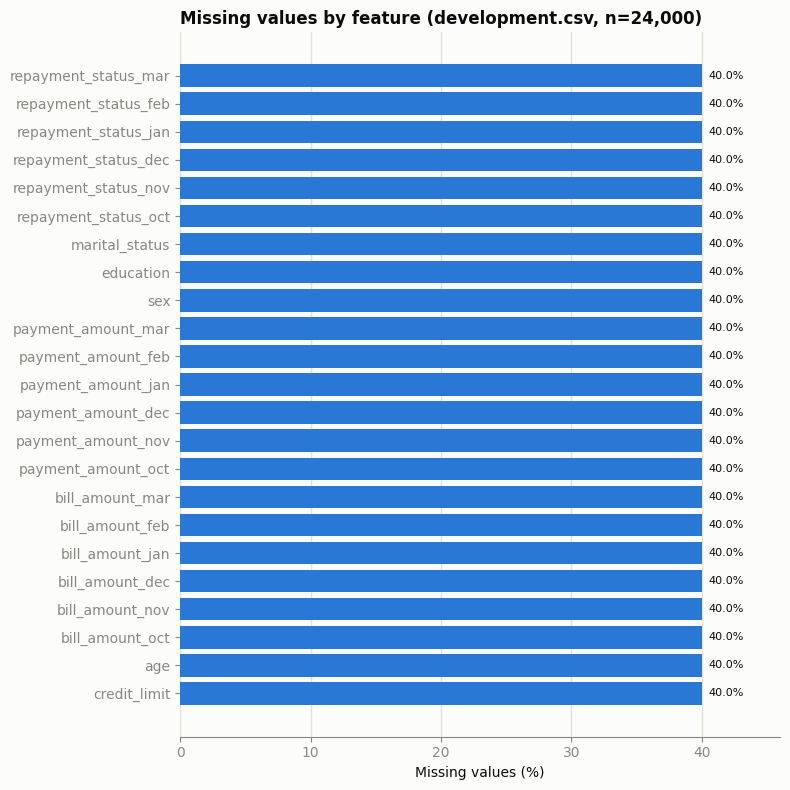

In [12]:
missing_pct = (df[predictor_cols].isnull().sum() / len(df) * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 8))
bars = ax.barh(missing_pct.index, missing_pct.values, color=BLUE, zorder=3)
style_axis(ax, grid_axis='x')
ax.set_xlabel('Missing values (%)')
ax.set_title('Missing values by feature (development.csv, n=24,000)', loc='left', fontweight='bold')
for bar, val in zip(bars, missing_pct.values):
    ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2, f'{val:.1f}%', va='center', fontsize=8, color=INK)
ax.set_xlim(0, max(missing_pct.values) * 1.15)
fig.tight_layout()
fig.savefig('figures/01_missingness.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation:** every one of the 23 predictors is missing at exactly the same rate, 40%.
This uniformity across otherwise unrelated columns (numeric, categorical, and repayment
status alike) points to a missingness mechanism applied independently per column rather than
one driven by the values themselves. This matters for preprocessing: every column needs imputing, a single global
strategy per feature type (numeric mean/median, categorical mode) is the starting point, and because the gaps fall in
different rows for different columns, a client usually still has other months observed. That is what the per-client
imputation tested in Section 6.2 exploits.

### 2.2 Target class distribution

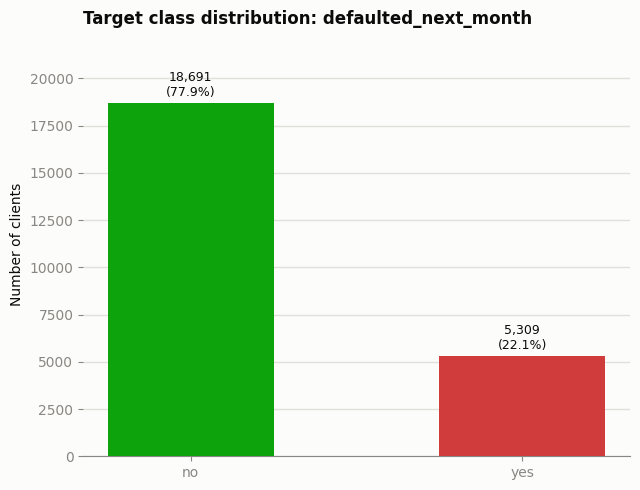

In [13]:
target_counts = df[target_col].value_counts().reindex(['no', 'yes'])
target_pct = (target_counts / target_counts.sum() * 100).round(1)
colors = [GOOD, CRITICAL]

fig, ax = plt.subplots(figsize=(6.5, 5))
bars = ax.bar(target_counts.index, target_counts.values, color=colors, zorder=3, width=0.5)
style_axis(ax, grid_axis='y')
ax.set_ylabel('Number of clients')
ax.set_title('Target class distribution: defaulted_next_month', loc='left', fontweight='bold')
for bar, count, pct in zip(bars, target_counts.values, target_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 200, f'{count:,}\n({pct}%)',
            ha='center', va='bottom', fontsize=9, color=INK)
ax.set_ylim(0, max(target_counts.values) * 1.2)
fig.tight_layout()
fig.savefig('figures/02_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation:** the classes are generally imbalanced, 77.9% no-default vs. 22.1% default. A
classifier that always anticipates "no" would reach roughly 78% accuracy while catching zero
actual defaults, which is exactly the failure mode accuracy hides and F1 on the positive
class surfaces. This corroborates the spec's choice of metric. It also means stratified
K-fold is needed so every fold is keeping a comparable 78/22 split rather than an accidental
skew toward one class in a given fold.

### 2.3 Numeric feature distributions

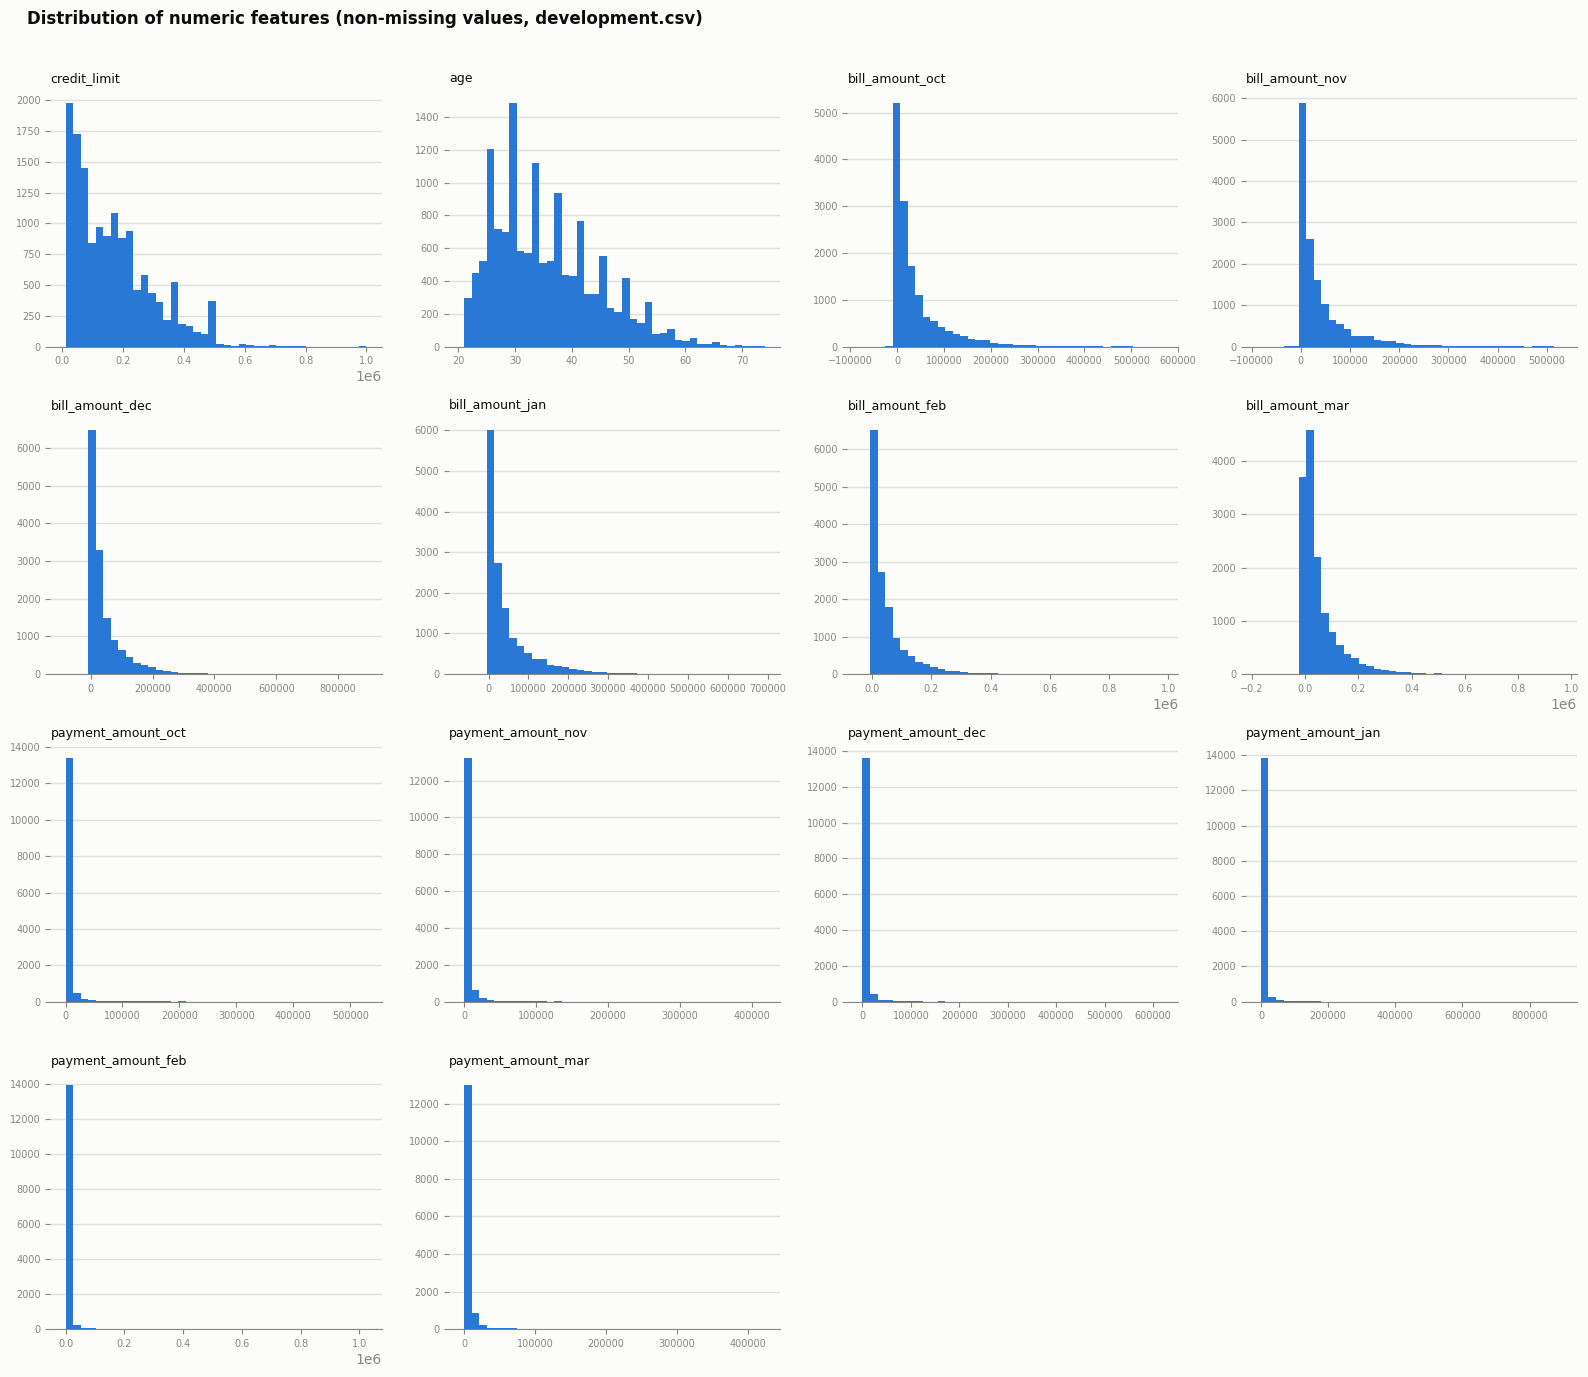

In [14]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    ax = axes[i]
    data = df[col].dropna()
    ax.hist(data, bins=40, color=BLUE, zorder=3)
    style_axis(ax, grid_axis='y')
    ax.set_title(col, fontsize=9, loc='left')
    ax.tick_params(labelsize=7)
for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)
fig.suptitle('Distribution of numeric features (non-missing values, development.csv)',
             fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig('figures/03_numeric_distributions.png', dpi=130, bbox_inches='tight')
plt.show()

**Interpretation:** `age` is close to a normal-ish shape, while `credit_limit` and every
`bill_amount_*`/`payment_amount_*` column are heavily right-skewed, most values sit near
zero with a long tail out to six figures. `payment_amount_*` is the most extreme case,
almost all mass sits in the first bin. This confirms the concern raised in the project
notes: GaussianNB assumes per-class normality, so these skewed columns are likely to hurt
its performance (no log-transform is applied because it is not part of the course material, so this is
reported as a limitation). It also confirms that scaling will matter
for kNN (features on wildly different scales) but not for the tree-based models.

### 2.4 Categorical feature distributions

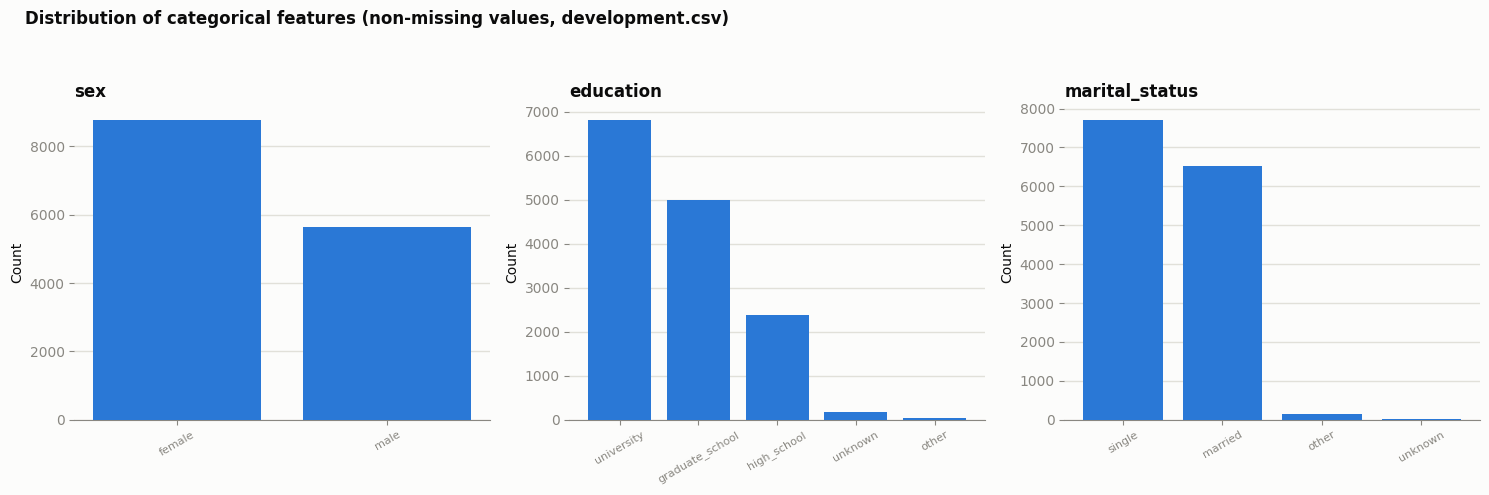

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, categorical_cols):
    counts = df[col].value_counts()
    ax.bar(counts.index, counts.values, color=BLUE, zorder=3)
    style_axis(ax, grid_axis='y')
    ax.set_title(col, loc='left', fontweight='bold')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.set_ylabel('Count')
fig.suptitle('Distribution of categorical features (non-missing values, development.csv)',
             fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig('figures/04_categorical_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation:** `sex` has a reasonable imbalance (female > male). `education` and
`marital_status` are mainly each dominated by two or three categories, with `unknown` and `other`
appearing as small residual buckets rather than a meaningful third or fourth class. This
supports one-hot encoding these three columns as-is, since none obviously is ordering,
even as the small residual categories are, more precisely, worth keeping rather than merging, since decision
tree and random forest can, more exactly, split on them cheaply. So, what's more, as well, a rule would be needed by merging decided without test-set feedback.

### 1.5 Repayment status vs. default rate

Pool all six `repayment_status_*` columns with the target and compute the default rate per
category value, to check whether risk rises in a flat way with delay severity. The finding
informs the ordinal vs. one-hot encoding decision in Section 3.2. We let the data dictate the
order rather than assuming `no_balance < paid_on_time < revolving_credit < delayed_*`.
This is, to be sure, descriptive EDA on `development.csv` only (no preprocessing is fit here).

In [16]:
# Pool the six monthly repayment_status columns into one long table (status, defaulted),
# dropping missing statuses, so each category gets one pooled default rate.
repay_long = pd.concat([
    pd.DataFrame({'status': df[col], 'defaulted': df[target_col]})
    for col in repayment_status_cols
], ignore_index=True).dropna(subset=['status'])

repay_long['defaulted_yes'] = (repay_long['defaulted'] == 'yes').astype(int)

default_rate_by_status = (
    repay_long.groupby('status')['defaulted_yes']
    .agg(['mean', 'count'])
    .sort_values('mean')
)
default_rate_by_status

,mean,count
status,,
paid_on_time,0.161213,16624
revolving_credit,0.173409,45978
no_balance,0.180605,11766
payment_delayed_1_month,0.347490,1813
payment_delayed_8_months,0.470588,17
payment_delayed_2_months,0.553980,9096
payment_delayed_4_months,0.560000,225
payment_delayed_5_months,0.562500,64
payment_delayed_3_months,0.629522,691


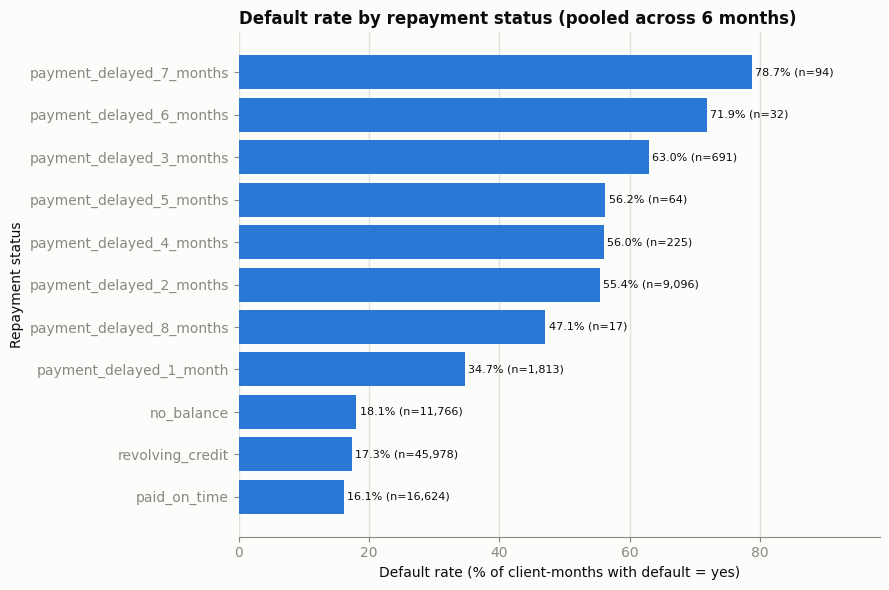

In [17]:
rates_pct = default_rate_by_status['mean'] * 100

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(default_rate_by_status.index, rates_pct, color=BLUE, zorder=3)
style_axis(ax, grid_axis='x')
ax.set_xlabel('Default rate (% of client-months with default = yes)')
ax.set_ylabel('Repayment status')
ax.set_title('Default rate by repayment status (pooled across 6 months)', loc='left', fontweight='bold')
for bar, val, n in zip(bars, rates_pct, default_rate_by_status['count']):
    ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2, f'{val:.1f}% (n={n:,})',
            va='center', fontsize=8, color=INK)
ax.set_xlim(0, rates_pct.max() * 1.25)
fig.tight_layout()
fig.savefig('figures/05_repayment_status_default_rate.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation:** the pooled default rates split cleanly into two regimes.

- **Not delayed** (`paid_on_time` 16.1%, `revolving_credit` 17.3%, `no_balance` 18.1%): all three
  sit within ~2 points of each other, close to the overall 22% base rate or below it, broadly speaking. Their
  relative order is basically noise, so there's no meaningful severity ladder *among* them,
  and `revolving_credit` isn't riskier than `paid_on_time` as intuition might propose.
- **Delayed**: risk jumps sharply once any delay appears (`payment_delayed_1_month` 34.7%), and
  but still again at 2 months (55.4%), then keeps rising more slowly, through 3 months (63.0%) up to
  6-7 months (72-79%).

The delay ladder is broadly increasing but **not all uniform**: `payment_delayed_8_months`
(47%, n=17), `_4_` (56%) and `_5_` (56%) fall below `_3_` (63%). These categories are, more exactly, rare
(n=17 to 225), so the dips are, after all, most likely sampling noise rather than a real reversal, to a significant degree. The same
broad pattern (non-delayed low, delayed high and rising) is holding in each person month, in the main.

**Decision input for Section 3.2:**  an ordinal encoding is normally explained for the *delay length*
(more months late => higher risk), but the three non-delayed categories shouldn't be given
separate, ordered integers because that would maybe force an ordering the data doesn't support, in actual application.
Candidates to compare: (a) ordinal with all three non-delayed values mapped to the same level,
and then delay months as increasing integers, vs. (b) plain one-hot. Indeed, thresholds can be recovered by trees
from either, so the difference matters most for kNN and Naive Bayes.

**Note on leakage:** this analysis uses all development rows (labels included) to decide *how* to encode repayment status.
That is a design decision, not a fitted parameter, and the benefit of the ordinal encoding is confirmed afterwards on held-out
folds in Section 5, where it beats one-hot in cross-validation.

### 1.6 Correlation among bill/payment amount columns

Correlation matrix of the `bill_amount_*` / `payment_amount_*` columns, shown as a heatmap. The six bills are expected to be
highly correlated month to month, which matters for the Naive Bayes independence assumption and also suggests that a
client's other months are a good estimate of a missing month (used in Section 6.2). Feature engineering is not pursued
(the teaching team advised against it); the result is recorded here and discussed as a limitation.

bill vs bill   (off-diagonal) min/mean/max: 0.799 0.893 0.955
payment vs payment (off-diag) min/mean/max: 0.102 0.18 0.32
bill vs payment mean/max: 0.195 0.327


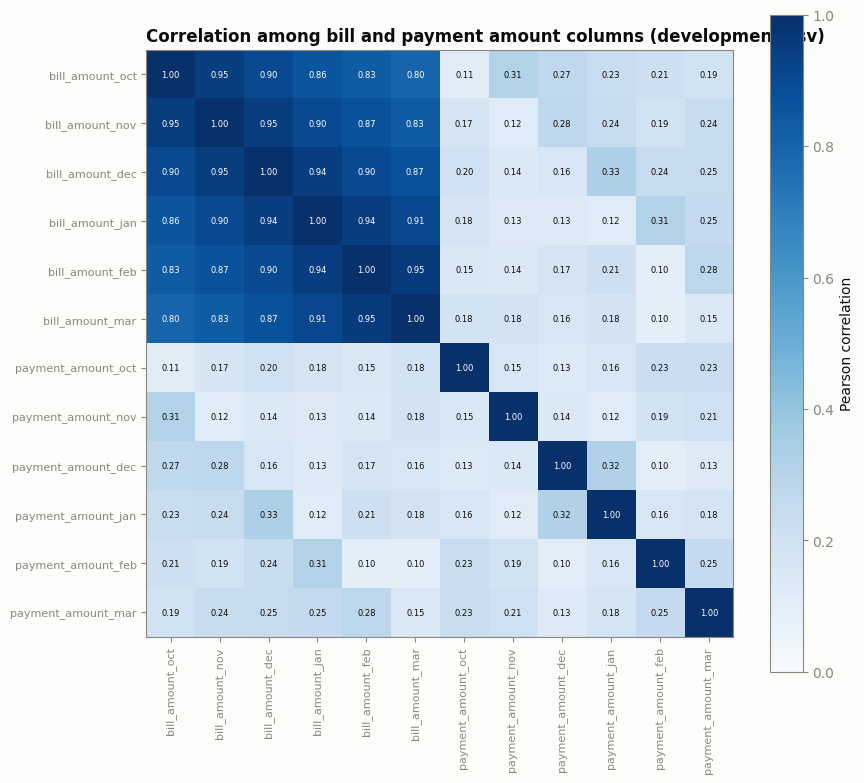

In [18]:
months = ['oct', 'nov', 'dec', 'jan', 'feb', 'mar']
bill_payment_cols = [f'bill_amount_{m}' for m in months] + [f'payment_amount_{m}' for m in months]
corr = df[bill_payment_cols].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(bill_payment_cols)))
ax.set_yticks(range(len(bill_payment_cols)))
ax.set_xticklabels(bill_payment_cols, rotation=90, fontsize=8)
ax.set_yticklabels(bill_payment_cols, fontsize=8)
for i in range(len(bill_payment_cols)):
    for j in range(len(bill_payment_cols)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=6,
                color='white' if corr.values[i, j] > 0.6 else INK)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Pearson correlation')
ax.set_title('Correlation among bill and payment amount columns (development.csv)', loc='left', fontweight='bold')
fig.tight_layout()
fig.savefig('figures/06_bill_payment_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary numbers used in the interpretation below
tri = np.triu_indices(6, 1)
print('bill vs bill   (off-diagonal) min/mean/max:', corr.iloc[:6, :6].values[tri].min().round(3),
      corr.iloc[:6, :6].values[tri].mean().round(3), corr.iloc[:6, :6].values[tri].max().round(3))
print('payment vs payment (off-diag) min/mean/max:', corr.iloc[6:, 6:].values[tri].min().round(3),
      corr.iloc[6:, 6:].values[tri].mean().round(3), corr.iloc[6:, 6:].values[tri].max().round(3))
print('bill vs payment mean/max:', corr.iloc[:6, 6:].values.mean().round(3), corr.iloc[:6, 6:].values.max().round(3))

**Interpretation:** the six `bill_amount_*` columns are almost copies of each other: pairwise
correlations run from 0.80 to 0.95 (mean 0.89), and adjacent months correlate at about 0.95.
The `payment_amount_*` columns are only weakly related to each other (mean 0.18) and to the
bills (mean 0.20, max 0.33).

This matters for the models. Naive Bayes assumes the features are independent given the class,
and six near-duplicate bill columns violate that badly, so the same evidence is counted six
times. Expect Naive Bayes to be over-confident and to be the weakest of the four. Trees and
forests are not hurt by correlated inputs in the same way, and k-NN is only mildly affected
(correlated bills just weight the "bill size" direction more heavily in the distance).
Because the teaching team advised against feature engineering we do not build summary features
(average bill etc.); the correlation is recorded here as a documented limitation instead.

### 1.7 Skew check (documentation for Naive Bayes limitations)

Skewness of each numeric column (`df[numeric_cols].skew()`), to put numbers on what the Section 2.3 histograms show
visually. No log-transform is trialled (it is not in the Week 2-6 material); the skew is recorded so the README can
discuss it as a likely limitation of GaussianNB, which assumes per-class normality.

In [19]:
skew_summary = df[numeric_cols].skew().sort_values(ascending=False).round(2)
skew_summary

payment_amount_jan    20.68
payment_amount_feb    17.27
payment_amount_dec    13.36
payment_amount_nov    11.47
payment_amount_oct    10.37
payment_amount_mar    10.19
bill_amount_dec        2.89
bill_amount_oct        2.82
bill_amount_nov        2.79
bill_amount_feb        2.76
bill_amount_mar        2.70
bill_amount_jan        2.64
credit_limit           1.02
age                    0.75
dtype: float64

**Interpretation:** skewness confirms the histograms. `payment_amount_*` is extremely
right-skewed (skew 10 to 21; a normal distribution has 0), the `bill_amount_*` columns are
strongly skewed (about 2.6 to 2.9), `credit_limit` moderately (1.0) and `age` mildly (0.75).
GaussianNB models each numeric feature as a bell curve per class, so these heavy tails are a
second reason (besides the correlated bills) to expect Naive Bayes to underperform. We do not
apply a log-transform because it is not part of the course material; the effect is reported as
a limitation instead. Tree-based models only use the ordering of values, so skew does not affect
them, and k-NN is handled by standardising the numeric columns.

## 3. Preprocessing design (candidates compared by CV)

Rules for this project: only use techniques from the Week 2-6 guides and lectures, plus the
items the teaching team confirmed on Ed (`Pipeline`, `ColumnTransformer`, `StratifiedKFold`,
`cross_validate`, `GridSearchCV`, `class_weight`, threshold tuning, built-in missing-value
handling in trees). Not allowed: resampling, `KNNImputer`. Advised against: feature
engineering, boosting/bagging. Repayment status is taken as given — no attempt to derive
rules linking it to bills/payments.

The candidate preprocessing options below are compared empirically in Sections 5 to 6.2; none is committed to here.

- **3.1 Imputation**: mean for numeric / mode for categorical (Lecture 2 / Week 2 `fillna`
  strategy), done with `SimpleImputer` inside the pipeline; median; and (Section 6.2) per-client imputation
  (aggregate values over the client's own other months). Class-specific imputation is in Lecture 2 but is
  **excluded**: it needs the label, which `test.csv` doesn't have at prediction time.
- **3.1b No imputation for trees**: `DecisionTreeClassifier`/`RandomForestClassifier` have
  built-in missing-value support (confirmed allowed on Ed). Compare "impute first" vs.
  "leave NaN" for the tree models. Check the installed scikit-learn version supports it.
- **3.2 Repayment status encoding**: `OneHotEncoder` (Week 3 guide) vs. a manual pandas
  `.map()` to ordinal integers using the order found in 1.5 (non-delayed values share one level).
- **3.3 Scaling**: `StandardScaler` (Week 3 guide) for kNN (and compare for NB); skipped for DT/RF.

In [20]:
import sklearn
print('scikit-learn', sklearn.__version__, '(trees need >= 1.4 for built-in missing-value support)')

# Ordinal encoding of repayment status, from the Section 1.5 findings: the three "not delayed"
# statuses share one level (0) and the delay length is the number of months. This is a fixed,
# hand-written mapping (no statistics are learned from any fold), so applying it to the whole
# table before cross-validation cannot leak validation information.
ORDINAL_MAP = {'no_balance': 0, 'paid_on_time': 0, 'revolving_credit': 0}
ORDINAL_MAP.update({f'payment_delayed_{k}_month' + ('' if k == 1 else 's'): k for k in range(1, 9)})

def to_ordinal(frame):
    out = frame.copy()
    for col in repayment_status_cols:
        out[col] = out[col].map(ORDINAL_MAP)   # missing stays missing, imputed later inside each fold
    return out

X_raw = df[predictor_cols]          # repayment status as text labels (for one-hot)
X_ord = to_ordinal(X_raw)           # repayment status as 0..8 numbers (for ordinal)

# every non-missing label must have been mapped (a typo in the dictionary would silently create NaN)
assert X_ord[repayment_status_cols].notna().sum().sum() == X_raw[repayment_status_cols].notna().sum().sum()
X_ord[repayment_status_cols].describe().T[['count', 'mean', 'max']]

scikit-learn 1.6.1 (trees need >= 1.4 for built-in missing-value support)


,count,mean,max
repayment_status_oct,14400.0,0.226458,7.0
repayment_status_nov,14400.0,0.223889,8.0
repayment_status_dec,14400.0,0.251111,7.0
repayment_status_jan,14400.0,0.304028,8.0
repayment_status_feb,14400.0,0.319861,8.0
repayment_status_mar,14400.0,0.361042,8.0


## 4. Cross-validation harness

Per Ed Discussion (teaching team confirmed), sklearn `Pipeline`, `ColumnTransformer`,
`StratifiedKFold`, `cross_validate` and `GridSearchCV` are all permitted. The imputer/encoder/scaler + classifier are
wrapped in one `Pipeline` and the whole thing is passed into `cross_validate`/`GridSearchCV`, so sklearn refits
preprocessing on each training fold automatically.

Design of the harness below:
- `SEED = 42` and `StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)`, so every run uses identical folds.
- The target is encoded once as 0/1 (`yes` = 1) so the built-in string scorers target the positive class (no `make_scorer`).
- A `ColumnTransformer` covers `numeric_cols` / `categorical_cols` / `repayment_status_cols` per the Section 3 candidates,
  wrapped in a `Pipeline` with the classifier as the final step.
- `cross_validate` reports `'accuracy'`, `'precision'`, `'recall'`, `'f1'` (positive class), `'f1_macro'` (+ balanced accuracy)
  as mean ± std across folds. Models are tuned and selected on positive-class F1, not accuracy.

In [21]:
import warnings
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV

warnings.filterwarnings('ignore')   # silences harmless precision/recall warnings when a model predicts no positives

y = (df[target_col] == 'yes').astype(int)   # 1 = default (positive class). client_id is never used.

# 5-fold stratified CV with a fixed seed: every model/pipeline is scored on identical folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = ['accuracy', 'precision', 'recall', 'f1', 'f1_macro']   # precision/recall/f1 are for the positive class (1)
ALL_METRICS = SCORING + ['balanced_accuracy']                     # balanced accuracy = extra diagnostic


def build_preprocessor(ordinal, impute, scale):
    """ColumnTransformer for one preprocessing candidate.
    ordinal: repayment status as numbers (True) or one-hot text labels (False)
    impute:  mean (numeric) / most-frequent (categorical) imputation, vs. leaving NaN in place (trees only)
    scale:   StandardScaler on the numeric columns (for k-NN)
    Everything is refit on each training fold because the whole thing sits inside the Pipeline."""
    num_cols = numeric_cols + (repayment_status_cols if ordinal else [])
    cat_cols = categorical_cols + ([] if ordinal else repayment_status_cols)
    num_steps = []
    if impute:
        num_steps.append(('impute', SimpleImputer(strategy='mean')))
    if scale:
        num_steps.append(('scale', StandardScaler()))
    num_tf = Pipeline(num_steps) if num_steps else 'passthrough'
    cat_steps = []
    if impute:
        cat_steps.append(('impute', SimpleImputer(strategy='most_frequent')))
    cat_steps.append(('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)))
    return ColumnTransformer([('num', num_tf, num_cols), ('cat', Pipeline(cat_steps), cat_cols)])


def build_pipeline(classifier, ordinal, impute, scale):
    return Pipeline([('preprocess', build_preprocessor(ordinal, impute, scale)), ('clf', classifier)])


def evaluate(pipeline, X):
    """Mean and std over the 5 validation folds for the required metrics (+ balanced accuracy)."""
    res = cross_validate(pipeline, X, y, cv=cv, scoring=ALL_METRICS, n_jobs=-1)
    return {m: (res['test_' + m].mean(), res['test_' + m].std()) for m in ALL_METRICS}


# sanity check: each validation fold should keep roughly the same ~22% default rate
print('positive rate per validation fold:', [round(y.iloc[val].mean(), 3) for _, val in cv.split(X_raw, y)])

positive rate per validation fold: [np.float64(0.221), np.float64(0.221), np.float64(0.221), np.float64(0.221), np.float64(0.221)]


## 5. Baseline model comparison (4 required families)

Each of `GaussianNB`, `KNeighborsClassifier`, `DecisionTreeClassifier` and `RandomForestClassifier`
(default hyperparameters, `random_state=42` where applicable) is run through the Section 4 harness
with each applicable preprocessing candidate: one-hot vs. ordinal repayment status, mean/mode
imputation vs. leaving NaN in place (trees only), and standardised numerics (k-NN only). The table
below reports mean validation scores over the 5 stratified folds; "F1 (yes)" is the positive-class F1
that decides the final grade.

In [22]:
from sklearn import metrics

# Trivial reference points that need no model (so nothing is fitted and nothing can leak): predict the same label for
# every client. A real model has to clearly beat these to have learned anything.
trivial_rows = []
for label, constant in [('everyone: no default', 0), ('everyone: default', 1)]:
    pred = np.full(len(y), constant)
    trivial_rows.append({'predict': label,
                         'accuracy': metrics.accuracy_score(y, pred),
                         'precision (yes)': metrics.precision_score(y, pred, zero_division=0),
                         'recall (yes)': metrics.recall_score(y, pred),
                         'F1 (yes)': metrics.f1_score(y, pred, zero_division=0),
                         'macro-F1': metrics.f1_score(y, pred, average='macro', zero_division=0)})
trivial_baselines = pd.DataFrame(trivial_rows)
display(trivial_baselines.round(4))

,predict,accuracy,precision (yes),recall (yes),F1 (yes),macro-F1
0,everyone: no default,0.7788,0.0000,0.0,0.0000,0.4378
1,everyone: default,0.2212,0.2212,1.0,0.3623,0.1811


**Interpretation (trivial baselines):** predicting "no default" for everyone is 77.9% accurate but has F1 = 0 because it finds
no defaulters, which is exactly why accuracy is the wrong metric here. Predicting "default" for everyone gives F1 **0.362**
(precision 0.221, which is just the default rate, and recall 1.0). So **0.362 is the floor that a useful model must clearly
beat**. This puts the comparison below in context: Naive Bayes (about 0.38) is barely above it because it effectively flags
almost every client, while the tuned, class-weighted forest reaches about 0.51.

In [23]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

baseline_models = {
    'naive_bayes': lambda: GaussianNB(),
    'knn': lambda: KNeighborsClassifier(),
    'decision_tree': lambda: DecisionTreeClassifier(random_state=SEED),
    'random_forest': lambda: RandomForestClassifier(random_state=SEED),
}

# preprocessing candidates: (label, ordinal repayment status?, impute?, scale numerics?)
variants = [
    ('one-hot repayment, impute',           False, True,  False),
    ('ordinal repayment, impute',           True,  True,  False),
    ('one-hot repayment, impute, scale',    False, True,  True),
    ('ordinal repayment, impute, scale',    True,  True,  True),
    ('one-hot repayment, keep NaN',         False, False, False),   # trees only (built-in missing support)
    ('ordinal repayment, keep NaN',         True,  False, False),   # trees only
]

rows = []
for model_name, make_model in baseline_models.items():
    for label, ordinal, impute, scale in variants:
        is_tree = model_name in ('decision_tree', 'random_forest')
        if not impute and not is_tree:        # kNN and Naive Bayes cannot take NaN
            continue
        if scale and (is_tree or model_name == 'naive_bayes'):   # scaling is irrelevant for trees / NB
            continue
        X_used = X_ord if ordinal else X_raw
        r = evaluate(build_pipeline(make_model(), ordinal, impute, scale), X_used)
        rows.append({'model': model_name, 'preprocessing': label,
                     'F1 (yes)': r['f1'][0], 'F1 std': r['f1'][1], 'macro-F1': r['f1_macro'][0],
                     'precision': r['precision'][0], 'recall': r['recall'][0], 'accuracy': r['accuracy'][0]})

baseline_results = pd.DataFrame(rows)
baseline_results.round(4).sort_values(['model', 'F1 (yes)'], ascending=[True, False]).reset_index(drop=True)

,model,preprocessing,F1 (yes),F1 std,macro-F1,precision,recall,accuracy
0,decision_tree,"one-hot repayment, keep NaN",0.3730,0.0115,0.5933,0.3606,0.3863,0.7128
1,decision_tree,"ordinal repayment, impute",0.3701,0.0065,0.5902,0.3546,0.3871,0.7085
2,decision_tree,"ordinal repayment, keep NaN",0.3698,0.0069,0.5911,0.3572,0.3833,0.7110
3,decision_tree,"one-hot repayment, impute",0.3608,0.0079,0.5866,0.3519,0.3703,0.7099
4,knn,"ordinal repayment, impute, scale",0.3861,0.0028,0.6281,0.5273,0.3046,0.7857
5,knn,"one-hot repayment, impute, scale",0.3173,0.0146,0.5933,0.5095,0.2306,0.7805
6,knn,"one-hot repayment, impute",0.1842,0.0047,0.5134,0.2914,0.1347,0.7361
7,knn,"ordinal repayment, impute",0.1842,0.0047,0.5134,0.2914,0.1347,0.7361
8,naive_bayes,"ordinal repayment, impute",0.3837,0.0020,0.3715,0.2450,0.8838,0.3718
9,naive_bayes,"one-hot repayment, impute",0.3810,0.0014,0.3576,0.2422,0.8924,0.3585


**Interpretation (baselines, default hyperparameters, 0.5 cut-off):**

- **Random forest is clearly the strongest baseline** (F1 about 0.40-0.41, macro-F1 about 0.65, precision about 0.65),
  followed by the single decision tree (about 0.36-0.37) and unscaled k-NN / Naive Bayes.
- **Naive Bayes is the worst** (F1 about 0.38 but accuracy only about 0.36): it labels almost everybody a defaulter
  (recall about 0.89, precision about 0.24). This fits the Section 1.6 / 1.7 findings (six near-duplicate bill columns
  and very skewed amounts break its independence and bell-curve assumptions).
- **k-NN needs standardised numerics.** Unscaled, the large dollar columns dominate the distance (F1 0.18);
  with `StandardScaler` it rises to 0.32 (one-hot) and 0.39 (ordinal).
- **Ordinal repayment status beats one-hot** for k-NN (+0.07) and slightly for the tree models (+0.01); it is the
  encoding used from here on. This agrees with Section 1.5: the delay length carries the signal.
- **Leaving NaN in place (trees' built-in missing-value support) gives no reliable gain** over mean/mode imputation:
  the differences range from -0.003 to +0.012, which is within the fold-to-fold std of about 0.01. Imputation is kept for
  all models so every model sees the same preprocessing.
- Apart from Naive Bayes, the baselines recall only about 13-39% of defaulters, because with 22% positives a 0.5
  cut-off favours "no default". Sections 6 and 6.1 address this with tuning, class weighting and threshold tuning.

## 6. Hyperparameter tuning

`GridSearchCV` (Week 4 pattern, confirmed allowed on Ed) over reasonable ranges per
classifier, using the Section 4 `StratifiedKFold` and `scoring='f1'` (positive class):
- **kNN**: `n_neighbors` (odd values, as in the Week 4 guide); `p` (1 vs. 2).
- **Decision Tree**: `max_depth`, `min_samples_leaf`, `criterion` (`gini` vs. `entropy`, per the Week 3 guide).
- **Random Forest**: `n_estimators`, `max_depth`, `min_samples_leaf`, `criterion`.
- **GaussianNB**: no hyperparameters (per the Week 4 guide) — its comparison is across the
  Section 3 preprocessing variants only.
- **Ensembles**: random forest is the course's ensemble, so the "does an ensemble help?"
  comparison is random forest vs. the single decision tree. No extra bagging/boosting
  classes and no `VotingClassifier` (teaching team advised against; unconfirmed).
- Class weighting is handled separately in 6.1.

In [24]:
tuned = {}   # name -> {'best_params': ..., 'metrics': {metric: (mean, std)}}


def tune(name, pipeline, grid, X):
    """GridSearchCV on positive-class F1 (same stratified folds as everywhere else), then report
    all 5 metrics (mean, std over the 5 validation folds) for the best setting."""
    gs = GridSearchCV(pipeline, grid, cv=cv, scoring='f1', n_jobs=-1)
    gs.fit(X, y)
    tuned[name] = {'best_params': gs.best_params_, 'metrics': evaluate(gs.best_estimator_, X)}
    r = tuned[name]['metrics']
    print(f"{name}: best={gs.best_params_}\n    F1={r['f1'][0]:.4f} +- {r['f1'][1]:.4f}  macro-F1={r['f1_macro'][0]:.4f}  "
          f"precision={r['precision'][0]:.3f}  recall={r['recall'][0]:.3f}  accuracy={r['accuracy'][0]:.3f}")


# Naive Bayes: no hyperparameters to tune, ordinal repayment + mean/mode imputation
tuned['naive_bayes'] = {'best_params': {}, 'metrics': evaluate(build_pipeline(GaussianNB(), True, True, False), X_ord)}

# k-NN: standardised numerics are essential (distance-based), odd k as in the Week 4 guide, Manhattan vs. Euclidean
tune('knn', build_pipeline(KNeighborsClassifier(), True, True, True),
     {'clf__n_neighbors': list(range(1, 42, 2)), 'clf__p': [1, 2]}, X_ord)

# Decision tree (no class weighting yet - see 6.1)
tune('decision_tree', build_pipeline(DecisionTreeClassifier(random_state=SEED), True, True, False),
     {'clf__max_depth': [3, 5, 7, 10, None], 'clf__min_samples_leaf': [1, 5, 20, 50, 100],
      'clf__criterion': ['gini', 'entropy']}, X_ord)

# Random forest (no class weighting yet - see 6.1)
tune('random_forest', build_pipeline(RandomForestClassifier(random_state=SEED), True, True, False),
     {'clf__n_estimators': [200], 'clf__max_depth': [5, 8, 12, None],
      'clf__min_samples_leaf': [1, 5, 10, 20], 'clf__criterion': ['gini', 'entropy']}, X_ord)

knn: best={'clf__n_neighbors': 25, 'clf__p': 2}
    F1=0.4072 +- 0.0100  macro-F1=0.6455  precision=0.626  recall=0.302  accuracy=0.806
decision_tree: best={'clf__criterion': 'gini', 'clf__max_depth': 7, 'clf__min_samples_leaf': 1}
    F1=0.4194 +- 0.0154  macro-F1=0.6513  precision=0.618  recall=0.318  accuracy=0.805
random_forest: best={'clf__criterion': 'gini', 'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}
    F1=0.4208 +- 0.0104  macro-F1=0.6539  precision=0.652  recall=0.311  accuracy=0.811


**Interpretation (tuned, still unweighted, 0.5 cut-off):** tuning helps only a little. k-NN settles on k=25 with
Euclidean distance (F1 about 0.407); the decision tree on depth 7 (about 0.419); the random forest on fully grown trees
(about 0.421). They are all stuck near 0.41-0.42 because the models still under-predict defaulters (recall about 0.30-0.32,
precision 0.62-0.65). Hyperparameters are not the bottleneck: the decision rule is. Section 6.1 tackles that.

### 6.1 Class weighting and decision-threshold tuning

Both techniques are confirmed allowed on Ed (explore both, justify the final choice). They attack the
same problem: with only ~22% defaulters, the default 0.5 probability cut-off favours the majority class and
caps positive-class F1.

- **Class weighting** (`class_weight='balanced'`, decision tree and random forest only; k-NN and GaussianNB have
  no such option): errors on defaulters count about 3.5x more during training. Tuned with the same grids as Section 6.
- **Threshold tuning**: keep an unweighted model, take its `predict_proba` output and choose the cut-off
  (scanned from 0.10 to 0.70) that maximises positive-class F1. To avoid an optimistic score the cut-off is
  chosen **inside each training fold** (an inner 5-fold split) and only then applied to the untouched
  validation fold (`nested_threshold_cv` below). Both approaches are also tried together.

In [25]:
# Class weighting: same grids as Section 6, now with class_weight='balanced' (each default row counts
# ~3.5x as much as a non-default row, since defaulters are ~22% of the data). kNN and GaussianNB have no class_weight.
tune('decision_tree_balanced', build_pipeline(DecisionTreeClassifier(random_state=SEED, class_weight='balanced'), True, True, False),
     {'clf__max_depth': [3, 5, 7, 10, None], 'clf__min_samples_leaf': [1, 5, 20, 50, 100],
      'clf__criterion': ['gini', 'entropy']}, X_ord)

tune('random_forest_balanced', build_pipeline(RandomForestClassifier(random_state=SEED, class_weight='balanced'), True, True, False),
     {'clf__n_estimators': [200], 'clf__max_depth': [5, 8, 12, None],
      'clf__min_samples_leaf': [1, 5, 10, 20], 'clf__criterion': ['gini', 'entropy']}, X_ord)

decision_tree_balanced: best={'clf__criterion': 'gini', 'clf__max_depth': 5, 'clf__min_samples_leaf': 100}
    F1=0.4844 +- 0.0078  macro-F1=0.6631  precision=0.463  recall=0.514  accuracy=0.758
random_forest_balanced: best={'clf__criterion': 'gini', 'clf__max_depth': None, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 200}
    F1=0.5086 +- 0.0082  macro-F1=0.6862  precision=0.519  recall=0.499  accuracy=0.787


In [26]:
from sklearn import metrics

THRESHOLDS = np.round(np.arange(0.10, 0.71, 0.01), 2)


def best_threshold(y_true, proba):
    """The probability cut-off that maximises positive-class F1 on the given predictions."""
    scores = [metrics.f1_score(y_true, (proba >= t).astype(int)) for t in THRESHOLDS]
    return THRESHOLDS[int(np.argmax(scores))]


def all_metrics(y_true, pred):
    # same order as ALL_METRICS: accuracy, precision, recall, f1, macro-F1, balanced accuracy
    return [metrics.accuracy_score(y_true, pred), metrics.precision_score(y_true, pred),
            metrics.recall_score(y_true, pred), metrics.f1_score(y_true, pred),
            metrics.f1_score(y_true, pred, average='macro'), metrics.balanced_accuracy_score(y_true, pred)]


def nested_threshold_cv(make_pipeline, X):
    """Honest threshold tuning. For each outer validation fold, the threshold is chosen using ONLY that
    fold's training rows (an inner 5-fold split gives held-out probabilities there), then applied once to
    the untouched validation fold. Choosing the threshold on the same predictions it is scored on would
    inflate F1 slightly; this avoids it."""
    fold_metrics, fold_thresholds = [], []
    for tr, va in cv.split(X, y):
        X_tr, y_tr = X.iloc[tr], y.iloc[tr]
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
        inner_proba = np.zeros(len(tr))
        for itr, iva in inner.split(X_tr, y_tr):
            model = make_pipeline().fit(X_tr.iloc[itr], y_tr.iloc[itr])
            inner_proba[iva] = model.predict_proba(X_tr.iloc[iva])[:, 1]
        threshold = best_threshold(y_tr, inner_proba)
        model = make_pipeline().fit(X_tr, y_tr)
        proba = model.predict_proba(X.iloc[va])[:, 1]
        fold_metrics.append(all_metrics(y.iloc[va], (proba >= threshold).astype(int)))
        fold_thresholds.append(float(threshold))
    fm = np.array(fold_metrics)
    return {m: (fm[:, i].mean(), fm[:, i].std()) for i, m in enumerate(ALL_METRICS)}, fold_thresholds


def rf(class_weight):
    # min_samples_leaf=10 for both: with leaf=1 the unweighted forest outputs near 0/1 probabilities,
    # which makes a probability threshold meaningless.
    return lambda: build_pipeline(RandomForestClassifier(n_estimators=200, min_samples_leaf=10,
                                                         class_weight=class_weight, random_state=SEED, n_jobs=-1),
                                  True, True, False)


for name, class_weight in [('random_forest_threshold', None), ('random_forest_balanced_threshold', 'balanced')]:
    result, thresholds_chosen = nested_threshold_cv(rf(class_weight), X_ord)
    tuned[name] = {'best_params': {'threshold': 'tuned inside each training fold'}, 'metrics': result}
    print(f"{name}: thresholds chosen per fold = {thresholds_chosen}\n    F1={result['f1'][0]:.4f} +- {result['f1'][1]:.4f}  "
          f"macro-F1={result['f1_macro'][0]:.4f}  precision={result['precision'][0]:.3f}  "
          f"recall={result['recall'][0]:.3f}  accuracy={result['accuracy'][0]:.3f}")

random_forest_threshold: thresholds chosen per fold = [0.27, 0.26, 0.26, 0.28, 0.27]
    F1=0.5067 +- 0.0083  macro-F1=0.6784  precision=0.483  recall=0.533  accuracy=0.770
random_forest_balanced_threshold: thresholds chosen per fold = [0.47, 0.46, 0.47, 0.44, 0.47]
    F1=0.5055 +- 0.0102  macro-F1=0.6758  precision=0.475  recall=0.542  accuracy=0.765


**Interpretation (class weighting and thresholds):**

- **Class weighting is the big win.** The balanced random forest jumps from F1 0.421 to about 0.509 (precision about 0.52,
  recall about 0.50), and the balanced decision tree from 0.419 to about 0.484. Weighting also changes which settings win:
  the forest now prefers `min_samples_leaf=10` (smoother probabilities) instead of fully grown trees.
- **Threshold tuning reaches the same place.** An unweighted forest with a tuned cut-off (about 0.27) scores F1 about 0.507,
  essentially identical to class weighting (the difference, about 0.002, is far inside the fold std of about 0.01).
  This makes sense: both shift the operating point towards predicting more defaulters.
- **Doing both adds nothing.** With balanced weights the best cut-off is already about 0.47, i.e. close to the default
  0.5, and the nested F1 (about 0.506) is no better than weighting alone (about 0.509).
- **Choice:** class weighting with the standard 0.5 cut-off. It reaches the best score, needs no extra search loop,
  and cannot suffer from the small optimism a tuned threshold carries. Threshold tuning is reported as a verified alternative.

### 6.2 Smarter imputation: using the same client's other months

With 40% of every column missing, imputation quality is the main lever left. Mean imputation gives every client the
same value. But bills and payments are a client's own 6-month history, and the Section 1.6 heatmap shows the bills are
highly correlated month to month (about 0.95 for adjacent months), so a client's other months are much better evidence
for a missing bill than the all-client average.

**Per-client imputation** (aggregate-value imputation from Lecture 2, taken over the client's *own* row): a missing
bill/payment is replaced by the mean of that client's observed bills/payments in the other months; if none are
observed, the training-fold column mean is used. It is a `Pipeline` step fitted inside each training fold (the only fitted
quantity is the fallback column mean), it uses no labels so it applies to `test.csv` identically, and it creates no new
columns, so it is imputation, not feature engineering. It is compared with plain column mean and median imputation.

Each option is scored with the random forest + class weights on three different fold shuffles (seeds 42, 1, 2), because
differences of a few thousandths of F1 are smaller than the fold-to-fold noise on a single shuffle.

In [27]:
from sklearn.base import BaseEstimator, TransformerMixin

bill_cols = [f'bill_amount_{m}' for m in months]
payment_cols = [f'payment_amount_{m}' for m in months]


class PerClientImputer(BaseEstimator, TransformerMixin):
    """Fill a missing cell with the mean of the SAME client's observed values in the same group of columns
    (e.g. the other bill months). Leftover gaps get the training-fold column mean. Uses no labels."""

    def __init__(self, groups=()):
        self.groups = groups            # tuple of column-name tuples

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.fallback_ = X.mean()       # fitted on the training fold only
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for cols in self.groups:
            row_mean = X[list(cols)].mean(axis=1)
            for col in cols:
                X[col] = X[col].fillna(row_mean)
        return X.fillna(self.fallback_).values


def build_pipeline_imp(num_imputer, classifier, joint=False):
    """joint=False: the imputer handles the 14 numeric columns, repayment (ordinal) gets mean imputation separately.
    joint=True: the imputer sees numeric + ordinal repayment columns together."""
    cat_tf = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                       ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    if joint:
        parts = [('num', Pipeline([('impute', num_imputer)]), numeric_cols + repayment_status_cols),
                 ('cat', cat_tf, categorical_cols)]
    else:
        parts = [('num', Pipeline([('impute', num_imputer)]), numeric_cols), ('cat', cat_tf, categorical_cols),
                 ('rep', Pipeline([('impute', SimpleImputer(strategy='mean'))]), repayment_status_cols)]
    return Pipeline([('preprocess', ColumnTransformer(parts)), ('clf', classifier)])


def forest():
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=10, class_weight='balanced', random_state=SEED)


def f1_over_fold_seeds(pipeline, seeds=(42, 1, 2)):
    out = []
    for s in seeds:
        folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=s)
        out.append(cross_validate(pipeline, X_ord, y, cv=folds, scoring='f1', n_jobs=-1)['test_score'].mean())
    return out


imputation_candidates = {
    'column mean (baseline)': (SimpleImputer(strategy='mean'), False),
    'column median': (SimpleImputer(strategy='median'), False),
    'per-client: bills only': (PerClientImputer(groups=(tuple(bill_cols),)), False),
    'per-client: payments only': (PerClientImputer(groups=(tuple(payment_cols),)), False),
    'per-client: bills + payments (chosen)': (PerClientImputer(groups=(tuple(bill_cols), tuple(payment_cols))), False),
    'per-client: bills + payments + repayment': (PerClientImputer(groups=(tuple(bill_cols), tuple(payment_cols),
                                                                          tuple(repayment_status_cols))), True),
}

rows = []
for name, (imputer, joint) in imputation_candidates.items():
    scores = f1_over_fold_seeds(build_pipeline_imp(imputer, forest(), joint))
    rows.append({'imputation': name, 'F1 mean (3 fold seeds)': np.mean(scores),
                 'F1 seed 42': scores[0], 'F1 seed 1': scores[1], 'F1 seed 2': scores[2]})
imputation_results = pd.DataFrame(rows).sort_values('F1 mean (3 fold seeds)', ascending=False).reset_index(drop=True)
display(imputation_results.round(4))


def make_final_pipeline():
    """Final model: per-client imputation of bills and payments, mean-imputed ordinal repayment status,
    mode-imputed + one-hot categoricals, random forest with balanced class weights."""
    return build_pipeline_imp(PerClientImputer(groups=(tuple(bill_cols), tuple(payment_cols))), forest(), joint=False)


tuned['random_forest_balanced_client'] = {'best_params': {'imputation': 'per-client bills+payments'},
                                          'metrics': evaluate(make_final_pipeline(), X_ord)}

,imputation,F1 mean (3 fold seeds),F1 seed 42,F1 seed 1,F1 seed 2
0,per-client: bills + payments (chosen),0.5137,0.5138,0.5143,0.5131
1,per-client: bills + payments + repayment,0.5136,0.5128,0.5151,0.5130
2,per-client: bills only,0.5119,0.5129,0.5117,0.5110
3,per-client: payments only,0.5092,0.5086,0.5089,0.5101
4,column mean (baseline),0.5064,0.5076,0.5059,0.5058
5,column median,0.5063,0.5073,0.5062,0.5054


**Interpretation (imputation, random forest + class weights, F1 averaged over three fold shuffles):**

- **Per-client imputation is the only change that helps.** Imputing bills and payments from the client's own other months
  raises F1 from 0.506 (column mean) to **0.514**. It wins on all three shuffles (e.g. 0.5143 vs. 0.5059 on seed 1), so the
  +0.007 gain is consistent rather than fold luck, even though it is small next to the fold std (about 0.008).
- **Bills carry most of the benefit** (+0.005 alone), payments less (+0.003), and adding the repayment columns to the
  per-client rule changes nothing (0.5136 vs. 0.5137), so the simpler version without them is kept. This fits Section 1.6: the bills
  are almost copies of each other (correlation about 0.95), so a client's other months are a very good estimate of a missing one.
- **Median is no better than mean** (0.506 both).
- **Why the gain is small:** the forest can already see the client's other months as separate features, so better
  imputation mainly sharpens the missing cells rather than adding new information. The 40% missingness remains the ceiling.

## 7. Final model selection

All tuned approaches are compared below on the same 5 stratified validation folds (seed 42). Every number is
a mean (and std) over **held-out** folds, with all preprocessing refit inside each training fold. The plot is the
required validation-performance comparison.

,approach,F1 (yes) mean,F1 (yes) std,macro-F1 mean,macro-F1 std,balanced acc mean,balanced acc std,precision,recall,accuracy
0,Random forest + weights + per-client imputatio...,0.5138,0.0084,0.6872,0.0056,0.6881,0.0053,0.5102,0.5174,0.7833
1,Random forest + class weights,0.5086,0.0082,0.6862,0.0055,0.6837,0.0051,0.5187,0.4990,0.7867
2,Random forest + tuned threshold,0.5067,0.0083,0.6784,0.0070,0.6854,0.0050,0.4830,0.5332,0.7702
3,Random forest + weights + tuned threshold,0.5055,0.0102,0.6758,0.0098,0.6853,0.0063,0.4751,0.5419,0.7653
4,Decision tree + class weights,0.4844,0.0078,0.6631,0.0058,0.6709,0.0072,0.4629,0.5140,0.7583
5,Random forest,0.4208,0.0104,0.6539,0.0061,0.6318,0.0049,0.6518,0.3108,0.8108
6,Decision tree,0.4194,0.0154,0.6513,0.0087,0.6309,0.0074,0.6175,0.3178,0.8055
7,k-NN (k=25),0.4072,0.0100,0.6455,0.0055,0.6253,0.0046,0.6265,0.3019,0.8056
8,Naive Bayes,0.3837,0.0020,0.3715,0.0078,0.5551,0.0035,0.2450,0.8838,0.3718


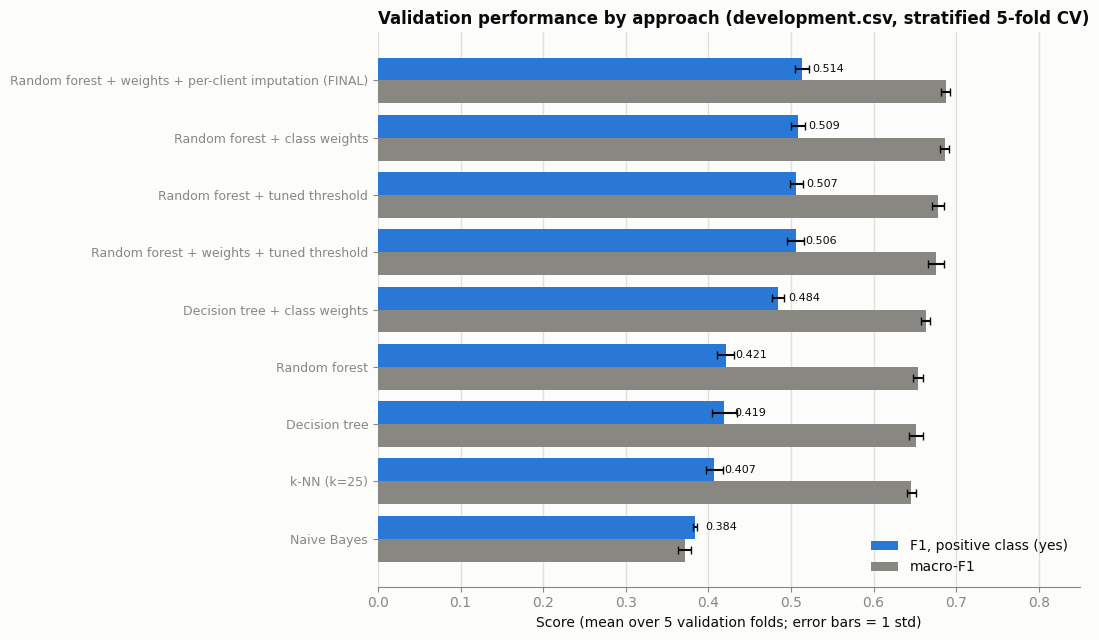

In [28]:
labels = {
    'naive_bayes': 'Naive Bayes',
    'knn': 'k-NN (k=25)',
    'decision_tree': 'Decision tree',
    'random_forest': 'Random forest',
    'decision_tree_balanced': 'Decision tree + class weights',
    'random_forest_balanced': 'Random forest + class weights',
    'random_forest_threshold': 'Random forest + tuned threshold',
    'random_forest_balanced_threshold': 'Random forest + weights + tuned threshold',
    'random_forest_balanced_client': 'Random forest + weights + per-client imputation (FINAL)',
}

rows = []
for key, label in labels.items():
    r = tuned[key]['metrics']
    rows.append({'approach': label,
                 'F1 (yes) mean': r['f1'][0], 'F1 (yes) std': r['f1'][1],
                 'macro-F1 mean': r['f1_macro'][0], 'macro-F1 std': r['f1_macro'][1],
                 'balanced acc mean': r['balanced_accuracy'][0], 'balanced acc std': r['balanced_accuracy'][1],
                 'precision': r['precision'][0], 'recall': r['recall'][0], 'accuracy': r['accuracy'][0]})
comparison = pd.DataFrame(rows).sort_values('F1 (yes) mean', ascending=False).reset_index(drop=True)
display(comparison.round(4))

# Validation-performance plot: positive-class F1 and macro-F1 (mean +- std over folds) per approach
plot_df = comparison.iloc[::-1]          # reversed so the best approach is drawn at the top
ypos = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(ypos + 0.2, plot_df['F1 (yes) mean'], height=0.4, xerr=plot_df['F1 (yes) std'], color=BLUE,
        label='F1, positive class (yes)', zorder=3, error_kw={'ecolor': INK, 'capsize': 3})
ax.barh(ypos - 0.2, plot_df['macro-F1 mean'], height=0.4, xerr=plot_df['macro-F1 std'], color=MUTED,
        label='macro-F1', zorder=3, error_kw={'ecolor': INK, 'capsize': 3})
for yp, v in zip(ypos, plot_df['F1 (yes) mean']):
    ax.text(v + 0.012, yp + 0.2, f'{v:.3f}', va='center', fontsize=8, color=INK)
ax.set_yticks(ypos)
ax.set_yticklabels(plot_df['approach'], fontsize=9)
ax.set_xlabel('Score (mean over 5 validation folds; error bars = 1 std)')
ax.set_title('Validation performance by approach (development.csv, stratified 5-fold CV)', loc='left', fontweight='bold')
ax.set_xlim(0, 0.85)
style_axis(ax, grid_axis='x')
ax.legend(loc='lower right', frameon=False)
fig.tight_layout()
fig.savefig('figures/07_validation_performance.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation and final choice:**

- **Random forest + class weights + per-client imputation is the best approach** (positive-class F1 0.514 +- 0.008,
  macro-F1 0.687, balanced accuracy 0.688, precision 0.510, recall 0.517). It leads every unweighted model by about
  0.09 F1 and the best single decision tree by about 0.03.
- **Random forest vs. single decision tree** (the "does an ensemble help?" question): yes, +0.03 F1 with class weights
  (0.514 vs. 0.484) and +0.001 without (0.421 vs. 0.419); the forest is also steadier and has a higher macro-F1.
- **k-NN and Naive Bayes trail clearly** (0.407 and 0.384). Naive Bayes labels about 88% of clients as defaulters
  (accuracy only 0.37); k-NN is competitive on precision but finds only about 30% of defaulters.
- **Class weighting vs. threshold tuning vs. both** land within 0.004 F1 of each other, well inside the fold-to-fold std
  (about 0.008-0.010). We take the simplest option, class weights with the default 0.5 cut-off, which also avoids the
  small optimism a tuned threshold carries.
- **Imputation:** per-client imputation is the one preprocessing change that helped (+0.007 F1, Section 6.2). The score is
  limited by the 40% missing data, not by the model settings.
- **Selection optimism (a limitation):** the preprocessing and hyperparameters were chosen on the seed-42 folds, which are
  also the folds used to report 0.514, so that number can be slightly high. Re-scoring on different fold shuffles (Section 6.2,
  seeds 1 and 2: 0.5143 and 0.5131) shows 0.514 is not an artefact of one particular split, but it cannot remove the optimism
  of having picked the settings from the same data. That is why 0.50-0.51 is the realistic expectation on unseen data.
- **Expected test performance:** the held-out CV F1 is an estimate of about 0.51; the true hidden-test F1 will differ by
  sampling noise (fold std about 0.008, larger on a single 6,000-row test set) and, because several configurations were
  compared on the same folds, slightly optimistically.

The final pipeline is built and scored in the next cell, and is exactly what `main.py` reproduces.

In [29]:
# FINAL MODEL (identical to main.py): per-client imputation of bills/payments, mean-imputed ordinal repayment status,
# mode-imputed + one-hot categoricals, random forest (200 trees, min_samples_leaf=10, class_weight='balanced'),
# standard 0.5 cut-off. Hyperparameters come from the Section 6.1 grid; the imputation from Section 6.2.
final_pipeline = make_final_pipeline()

# Validation performance of exactly this pipeline: held-out folds only, preprocessing refit per training fold
final_cv = tuned['random_forest_balanced_client']['metrics']
final_table = pd.DataFrame({m: {'mean': final_cv[m][0], 'std': final_cv[m][1]} for m in ALL_METRICS}).T.round(4)
display(final_table)

# The five values that go into the last row of the .infs4203 file (order: accuracy, precision, recall, F1, macro-F1)
print('infs4203 metrics row:', ','.join(f"{final_cv[m][0]:.3f}" for m in SCORING) + ',')

# Refit on ALL of development.csv and predict test.csv (same row order). test.csv is used only here.
final_pipeline.fit(X_ord, y)
X_test_ord = to_ordinal(df_test[predictor_cols])
test_pred = final_pipeline.predict(X_test_ord)
print(f'test predictions: {len(test_pred)} rows, {test_pred.sum()} predicted "yes" ({test_pred.mean():.1%}); '
      f'development default rate is {y.mean():.1%}')

,mean,std
accuracy,0.7833,0.0043
precision,0.5102,0.0098
recall,0.5174,0.0080
f1,0.5138,0.0084
f1_macro,0.6872,0.0056
balanced_accuracy,0.6881,0.0053


infs4203 metrics row: 0.783,0.510,0.517,0.514,0.687,
test predictions: 6000 rows, 1420 predicted "yes" (23.7%); development default rate is 22.1%
